# highD 高速公路车辆速度过程的记忆效应检验

**研究问题**：把车辆在 $t$ 时刻的有向纵向速度 $v_t$ 当作系统状态时，速度的演化是否满足一阶马尔科夫假设
$P(v_{t+1}\mid v_t, v_{t-1}, \dots) = P(v_{t+1}\mid v_t)$？
如果不满足，历史速度就携带着当前速度之外的额外信息——这就是本文所说的**记忆效应**。

**为什么用三条互补的证据线**：任何单一检验都有盲点，所以我们从三个视角分别回答同一个问题，再看结论是否一致。

| 方法 | 视角 | 回答的问题 | 若一阶马尔科夫成立，应看到 |
|---|---|---|---|
| A. 马尔科夫阶数比较 | 样本外预测 | 增加历史长度 $k$ 能否提高**验证集**对数似然？ | $k\ge 1$ 后验证集 LL 不再提升，BIC 在 $k=1$ 最小 |
| B. 似然比检验 (LRT) | 统计推断 | 二阶模型相对一阶模型的似然提升是否超出抽样噪声？ | $G=2\Delta LL$ 与自由度同量级，$p$ 不显著 |
| C. VACF + GLE 记忆核 | 连续物理过程 | 速度涨落的记忆核 $K(t)$ 是否退化为 $\delta$ 函数？ | VACF 为单指数，$K(t>0)\approx 0$ |

- 方法 A 的盲点：结果依赖离散化（状态数、分箱方式），且大样本下微小提升也"显著"，所以要同时看**效应量**（每步提升多少 nats）。
- 方法 B 的盲点：全样本推断，不是样本外评估；在 $7.7\times10^6$ 步下几乎任何偏离都会被拒绝，所以 $p$ 值本身信息量有限，主要看 $\Delta LL/\text{step}$。
- 方法 C 的盲点：只刻画二阶矩（线性）记忆，并且 Volterra 反演对长滞后的数值误差敏感——本 notebook 会专门检查这一点。

**如何运行**：`RUN_COMPUTE = False` 时直接读取 `memory_analysis_output_8.0/` 中缓存的实验结果（本文件已据此执行）；
设为 `True` 则从 `data/*_tracks.csv` 重新计算（60 个文件，单进程约 10 分钟）。缓存不存在时自动回退到重新计算。

依赖：`pandas numpy scipy matplotlib`，可选 `tqdm`。

In [1]:
import os, glob, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
from scipy import stats
from scipy.optimize import curve_fit

try:
    from tqdm import tqdm
except ImportError:                      # tqdm 只负责进度条，缺失时退化为普通迭代
    tqdm = lambda x, **k: x

RUN_COMPUTE = False                      # True: 从 data/ 重新计算所有结果
DATA_GLOB   = './data/*_tracks.csv'
OUTPUT_DIR  = './memory_analysis_output_8.0'
os.makedirs(OUTPUT_DIR, exist_ok=True)

CFG = dict(
    velocity_mode = 'signed_longitudinal_velocity',  # 有向纵向速度（保留正负号）
    raw_dt_sec    = 0.04,    # highD 原始采样 25 Hz
    downsample    = 5,       # 5 倍降采样 -> dt_eff = 0.2 s
    n_states      = 20,      # 全局等频速度状态数
    max_order     = 3,       # 比较 k = 0..3 阶
    min_frames_raw= 50,      # 原始帧数不足 50 的车辆丢弃
    n_splits      = 5,       # 随机 train/val 划分次数
    train_frac    = 0.8,
    laplace_alpha = 1.0,     # add-alpha 平滑
    vacf_max_lag_sec = 8.0,  # VACF / K(t) 最大滞后
    vacf_mean_mode = 'per_trajectory',  # 'per_trajectory' (与缓存结果一致) 或 'global'
)
CFG['dt_eff_sec'] = CFG['raw_dt_sec'] * CFG['downsample']

CACHE = {k: os.path.join(OUTPUT_DIR, v) for k, v in dict(
    markov_results='markov_likelihood_results.csv',
    markov_summary='markov_likelihood_summary.csv',
    markov_sig='markov_significance_results.json',
    lrt='lrt_test_result.json',
    vacf_npz='vacf_kernel_data.npz',
    vacf_summary='vacf_kernel_summary.json').items()}

NEED_DATA = RUN_COMPUTE or not all(os.path.exists(p) for p in CACHE.values())
print('dt_eff = %.2f s | n_states = %d | 重新计算: %s' % (CFG['dt_eff_sec'], CFG['n_states'], NEED_DATA))

dt_eff = 0.20 s | n_states = 20 | 重新计算: False


## 1. 参数为什么这样选

- **状态变量 = 有向纵向速度**而不是位置：高速路上位置几乎单调递增，相邻帧位置几乎不变，用位置做状态会把一切都预测成"留在原地"，看不到动力学。速度由 $x$ 坐标中心差分得到：$v_t = (x_{t+1}-x_{t-1})/(2\,\Delta t)$，保留正负号，因此状态同时编码行驶方向。若要分析速率 $|v|$，必须改用 `np.abs(v)` 并重算全部结果。
- **5 倍降采样 (0.2 s)**：25 Hz 下相邻两帧速度几乎相同，任何模型都能"预测"出下一帧等于当前帧，记忆效应会被这种平凡相关淹没；0.2 s 既让相邻状态真有变化，又保留亚秒级动力学。
- **20 个等频 (quantile) 状态**：等频分箱让边际熵固定为 $\ln 20 \approx 2.996$ nats，于是 $k=0$ 模型的 LL/step 应当约等于 $-2.996$，这是后面检查代码是否正确的一个"锚点"。
- **按车辆划分 train/val**：同一辆车的序列只会出现在一侧，防止相邻时刻的信息泄露；quantile 边界只在训练集上估计。
- **Laplace 平滑 $\alpha=1$**：对 20 个状态，每个历史上下文只分摊 20 个"伪计数"，相对于每上下文数千次观测影响很小。

In [2]:
def load_speed_sequences(file_list, min_frames, downsample, dt):
    # 返回每辆车的有向纵向速度序列（中心差分 + 降采样）
    sequences = []
    for f in tqdm(file_list, desc='读取 tracks'):
        df = pd.read_csv(f, usecols=['id', 'frame', 'x'])
        for _, g in df.groupby('id'):
            if len(g) < min_frames:
                continue
            x = g.sort_values('frame')['x'].to_numpy(np.float64)
            v = (x[2:] - x[:-2]) / (2.0 * dt)
            v = v[::downsample]
            if len(v) >= 5:
                sequences.append(v.astype(np.float32))
    return sequences


def discretize_global(sequences, n_bins, edges=None):
    # 全局等频分箱；edges=None 时在给定序列上估计分位数边界（只应传训练集）
    if edges is None:
        all_v = np.concatenate(sequences)
        edges = np.quantile(all_v, np.linspace(0, 1, n_bins + 1))
        edges[0], edges[-1] = -np.inf, np.inf
    disc = [np.clip(np.searchsorted(edges, v, side='right') - 1, 0, n_bins - 1).astype(np.int32)
            for v in sequences]
    return disc, edges


if NEED_DATA:
    file_list = sorted(glob.glob(DATA_GLOB))
    assert file_list, f'找不到数据: {DATA_GLOB}'
    sequences = load_speed_sequences(file_list, CFG['min_frames_raw'], CFG['downsample'], CFG['raw_dt_sec'])
    lens = np.array([len(s) for s in sequences])
    print(f'文件数 {len(file_list)} | 轨迹数 {len(sequences)} | 降采样后总步数 {lens.sum()} | 序列长度中位数 {np.median(lens):.0f}')
else:
    print('使用缓存结果（2026-05-28 运行）: 60 个文件 | 110093 条轨迹 | 7926563 步 | 序列长度中位数 67')

使用缓存结果（2026-05-28 运行）: 60 个文件 | 110093 条轨迹 | 7926563 步 | 序列长度中位数 67


## 2. 方法 A：马尔科夫阶数比较（预测视角）

**目的**：对 $k=0,1,2,3$ 拟合 $k$ 阶马尔科夫链 $P(s_{t+1}\mid s_t,\dots,s_{t-k+1})$，比较它们在**验证集**上的 per-step 对数似然。
如果 $v_t$ 已经是完备状态，那么 $k=2,3$ 相对 $k=1$ 不应带来验证集上的提升。

**怎么读结果**：

- `val_ll_per_step` 随 $k$ 的增量 $\Delta_{k\to k+1}$ 是效应量：每多看一步历史，平均每步多"解释"多少 nats。
- `val_perplexity` $=\exp(-\text{LL/step})$ 是"有效候选状态数"，比 nats 更直观（20 个状态下完全无信息时为 20）。
- `train_bic` $=-2\,LL_{train} + p_{\text{eff}}\ln n$，其中 $p_{\text{eff}}$ 只计入**实际出现过**的历史上下文（名义参数量 $20^k\times19$ 会严重高估）。
- 训练集与验证集 LL 若几乎相同，说明没有过拟合；若训练集明显更高，则高阶提升可能是记住了噪声。
- 配对检验：对 split 0 的每条验证序列分别算 $k$ 与 $k+1$ 阶的 LL/step，做单侧 Wilcoxon 符号秩检验（$H_1$：高阶更好）。

**期望**：若存在记忆，$\Delta_{1\to2}>0$ 且显著，BIC 在 $k=1$ 之后继续下降；$\Delta$ 随 $k$ 递减则说明记忆主要集中在最近几步。

In [3]:
def fit_markov_k(sequences, k, n_states, alpha):
    # k 阶马尔科夫链（k=0 为边际分布），add-alpha 平滑；未见过的历史回退到边际分布
    marginal = np.full(n_states, alpha)
    for s in sequences:
        marginal += np.bincount(s, minlength=n_states)
    log_marginal = np.log(marginal / marginal.sum())
    log_probs = {}
    if k >= 1:
        counts = defaultdict(lambda: np.zeros(n_states))
        for s in sequences:
            for t in range(len(s) - k):
                counts[tuple(s[t:t + k].tolist())][s[t + k]] += 1.0
        for hist, c in counts.items():
            c = c + alpha
            log_probs[hist] = np.log(c / c.sum())
    return {'k': k, 'log_marginal': log_marginal, 'log_probs': log_probs}


def per_seq_loglik(model, sequences):
    # 每条序列的 (总 LL, 步数)
    k, lm, lp = model['k'], model['log_marginal'], model['log_probs']
    out = []
    for s in sequences:
        if k == 0:
            out.append((float(lm[s].sum()), len(s)))
            continue
        ll, n = 0.0, 0
        for t in range(len(s) - k):
            hist = tuple(s[t:t + k].tolist())
            ll += lp[hist][s[t + k]] if hist in lp else lm[s[t + k]]
            n += 1
        out.append((ll, n))
    return np.array(out)


def n_effective_params(model, n_states):
    return (n_states - 1) * (1 if model['k'] == 0 else len(model['log_probs']))


def run_markov_comparison(sequences, cfg, seed_base=0):
    rows, per_seq = [], {}
    n_seq = len(sequences)
    for split in range(cfg['n_splits']):
        idx = np.random.default_rng(seed_base + split).permutation(n_seq)
        cut = int(cfg['train_frac'] * n_seq)
        train_raw = [sequences[i] for i in idx[:cut]]
        val_raw = [sequences[i] for i in idx[cut:]]
        train, edges = discretize_global(train_raw, cfg['n_states'])     # 边界只用训练集
        val, _ = discretize_global(val_raw, cfg['n_states'], edges)
        for k in range(cfg['max_order'] + 1):
            m = fit_markov_k(train, k, cfg['n_states'], cfg['laplace_alpha'])
            tr, va = per_seq_loglik(m, train), per_seq_loglik(m, val)
            ll_tr, n_tr = tr[:, 0].sum(), tr[:, 1].sum()
            ll_va, n_va = va[:, 0].sum(), va[:, 1].sum()
            p_eff = n_effective_params(m, cfg['n_states'])
            rows.append(dict(split=split, k=k, n_params_eff=p_eff, n_train_steps=n_tr, n_val_steps=n_va,
                             train_ll_per_step=ll_tr / n_tr, val_ll_per_step=ll_va / n_va,
                             val_perplexity=np.exp(-ll_va / n_va),
                             train_bic=-2 * ll_tr + p_eff * np.log(n_tr)))
            if split == 0:
                per_seq[k] = va[:, 0] / np.maximum(va[:, 1], 1)
        print(f'  split {split + 1}/{cfg["n_splits"]} 完成')
    df = pd.DataFrame(rows)
    summary = df.groupby('k').agg(n_params_eff=('n_params_eff', 'mean'),
                                  train_ll_mean=('train_ll_per_step', 'mean'), train_ll_std=('train_ll_per_step', 'std'),
                                  val_ll_mean=('val_ll_per_step', 'mean'), val_ll_std=('val_ll_per_step', 'std'),
                                  val_perplexity_mean=('val_perplexity', 'mean'), bic_mean=('train_bic', 'mean')).reset_index()
    sig = []
    for k in range(cfg['max_order']):
        d = per_seq[k + 1] - per_seq[k]
        stat, p = stats.wilcoxon(d[d != 0], alternative='greater')
        sig.append(dict(from_k=k, to_k=k + 1, mean_delta=float(d.mean()), wilcoxon_p=float(p),
                        test_statistic=float(stat), test_method='scipy.stats.wilcoxon'))
    return df, summary, sig


if NEED_DATA:
    t0 = time.time()
    df_A, summary_A, sig_A = run_markov_comparison(sequences, CFG)
    df_A.to_csv(CACHE['markov_results'], index=False)
    summary_A.to_csv(CACHE['markov_summary'], index=False)
    json.dump(sig_A, open(CACHE['markov_sig'], 'w', encoding='utf-8'), indent=2)
    print(f'方法 A 耗时 {time.time() - t0:.0f} s')
else:
    df_A = pd.read_csv(CACHE['markov_results'])
    summary_A = pd.read_csv(CACHE['markov_summary'])
    sig_A = json.load(open(CACHE['markov_sig'], encoding='utf-8'))

tab = summary_A.copy()
tab['train LL/step'] = tab.apply(lambda r: f"{r.train_ll_mean:.4f} ± {r.train_ll_std:.4f}", axis=1)
tab['val LL/step'] = tab.apply(lambda r: f"{r.val_ll_mean:.4f} ± {r.val_ll_std:.4f}", axis=1)
tab['BIC (×1e6)'] = (tab.bic_mean / 1e6).round(4)
display(tab[['k', 'n_params_eff', 'train LL/step', 'val LL/step', 'val_perplexity_mean', 'BIC (×1e6)']].round(3))

val = summary_A.set_index('k')['val_ll_mean']
deltas_A = {f'{k}->{k+1}': val[k + 1] - val[k] for k in range(len(val) - 1)}
print('验证集 LL/step 增量 (nats):', {k: round(v, 4) for k, v in deltas_A.items()})
print('k=0 的 LL/step 应接近 -ln(20) = %.4f  -> 实际 %.4f' % (-np.log(20), val[0]))
display(pd.DataFrame(sig_A)[['from_k', 'to_k', 'mean_delta', 'wilcoxon_p', 'test_method']])

验证集 LL/step 增量 (nats): {'0->1': np.float64(2.5988), '1->2': np.float64(0.1034), '2->3': np.float64(0.0292)}
k=0 的 LL/step 应接近 -ln(20) = -2.9957  -> 实际 -2.9953


,k,n_params_eff,train LL/step,val LL/step,val_perplexity_mean,BIC (×1e6)
0,0,19.0,-2.9952 ± 0.0002,-2.9953 ± 0.0002,19.991,37.976
1,1,380.0,-0.3972 ± 0.0007,-0.3965 ± 0.0014,1.487,4.972
2,2,2755.0,-0.2934 ± 0.0005,-0.2931 ± 0.0009,1.341,3.660
3,3,10579.2,-0.2643 ± 0.0004,-0.2639 ± 0.0005,1.302,3.377


,from_k,to_k,mean_delta,wilcoxon_p,test_method
0,0,1,2.594679,0.0,normal_approx_average_ranks
1,1,2,0.105410,0.0,normal_approx_average_ranks
2,2,3,0.028705,0.0,normal_approx_average_ranks


### 方法 A 结果解读

1. **锚点检查通过**：$k=0$ 的 LL/step $=-2.9953\approx-\ln 20$，说明离散化与似然计算正确。
2. **一阶马尔科夫近似不足**：验证集 LL/step 从 $k=1$ 的 $-0.3965$ 提升到 $k=2$ 的 $-0.2931$（$\Delta_{1\to2}=+0.1034$ nats），再到 $k=3$ 的 $-0.2639$（$\Delta_{2\to3}=+0.0292$ nats）。换算成困惑度：有效候选状态数从 1.49 降到 1.34 再到 1.30。
3. **不是过拟合**：训练集与验证集 LL 几乎一致（$k=3$：$-0.2643$ vs $-0.2639$），$7.9\times10^6$ 步的样本量足以支撑 $10^4$ 量级的有效参数。
4. **记忆集中在最近几步**：增量按 $2.60 \to 0.103 \to 0.029$ 快速衰减（每升一阶约缩小到 1/3~1/25），说明最重要的额外信息来自 $s_{t-1}$，再往前的收益迅速递减；但 BIC 到 $k=3$ 仍在下降，说明在当前样本量下三阶历史仍有可识别的贡献。
5. 配对 Wilcoxon 检验 $p$ 在三次比较中均数值下溢为 0（验证集约 2.2 万条序列）；这说明提升是系统性的，而非少数序列拉动。

**结论（A）**：在"仅以当前有向纵向速度为状态"的表示下，速度过程不是一阶马尔科夫的；主导的额外信息来自一步历史，二步历史仍有小而稳定的贡献。

## 3. 方法 B：似然比检验（推断视角）

**目的**：在同一离散状态空间上做正式的假设检验。

- $H_0$：$P(s_{t+1}\mid s_t, s_{t-1}) = P(s_{t+1}\mid s_t)$（一阶足够）
- $H_1$：$s_{t-1}$ 仍携带信息（需要二阶）

统计量 $G = 2\,(LL_2 - LL_1)$ 在 $H_0$ 下渐近服从 $\chi^2_{df}$。两种自由度：

- **经验自由度** $df_{\text{emp}} = (\#\text{观测到的二阶上下文} - \#\text{一阶上下文})\times(|S|-1)$，只计入数据中真正出现过的上下文；
- **名义自由度** $df_{\text{nom}} = |S|(|S|-1)^2$，即无平滑时的完整参数差。

两种自由度给出的 $p$ 值若一致，结论就不依赖自由度的算法。

**注意**：这里一阶与二阶模型都在**全样本**上拟合并评估，是推断而非样本外预测；评估只在 $t\ge1$（存在 $s_{t-1}$）的步上进行，所以 $\Delta LL/\text{step}$ 与方法 A 的验证集增量定义不同，不能直接相等，只应比较符号与量级。

In [4]:
def likelihood_ratio_test(disc, n_states, alpha):
    m1 = fit_markov_k(disc, 1, n_states, alpha)
    m2 = fit_markov_k(disc, 2, n_states, alpha)
    ll1 = ll2 = 0.0
    n = 0
    for s in disc:
        for t in range(len(s) - 2):
            prev, curr, nxt = int(s[t]), int(s[t + 1]), int(s[t + 2])
            ll1 += m1['log_probs'][(curr,)][nxt] if (curr,) in m1['log_probs'] else m1['log_marginal'][nxt]
            ll2 += m2['log_probs'][(prev, curr)][nxt] if (prev, curr) in m2['log_probs'] else m2['log_marginal'][nxt]
            n += 1
    G = 2.0 * (ll2 - ll1)
    df_emp = max(1, (len(m2['log_probs']) - len(m1['log_probs'])) * (n_states - 1))
    df_nom = n_states * (n_states - 1) ** 2
    return dict(G_statistic=G, ll_1order=ll1, ll_2order=ll2, n_steps_compared=n,
                delta_ll_per_step=(ll2 - ll1) / n, df_empirical=df_emp, df_nominal=df_nom,
                p_value_empirical_df=float(stats.chi2.sf(G, df_emp)),
                p_value_nominal_df=float(stats.chi2.sf(G, df_nom)))


if NEED_DATA:
    disc_all, _ = discretize_global(sequences, CFG['n_states'])   # 全样本推断：边界用全部数据
    lrt = likelihood_ratio_test(disc_all, CFG['n_states'], CFG['laplace_alpha'])
    json.dump(lrt, open(CACHE['lrt'], 'w'), indent=2)
else:
    lrt = json.load(open(CACHE['lrt']))

# 把 G 与自由度放在同一尺度：H0 下 G 的期望 = df，标准差 = sqrt(2 df)
z_emp = (lrt['G_statistic'] - lrt['df_empirical']) / np.sqrt(2 * lrt['df_empirical'])
print(f"比较步数 n = {lrt['n_steps_compared']:,}")
print(f"LL(1阶) = {lrt['ll_1order']:,.1f}   LL(2阶) = {lrt['ll_2order']:,.1f}   ΔLL/step = {lrt['delta_ll_per_step']:+.4f} nats")
print(f"G = {lrt['G_statistic']:,.1f}   df_emp = {lrt['df_empirical']}   df_nom = {lrt['df_nominal']}")
print(f"H0 下 G 的期望约等于 df；实际 G 比 df_emp 高 {z_emp:,.0f} 个标准差")
print(f"p (经验 df) = {lrt['p_value_empirical_df']:.3g}   p (名义 df) = {lrt['p_value_nominal_df']:.3g}   (0 表示数值下溢)")

比较步数 n = 7,706,377
LL(1阶) = -2,795,987.3   LL(2阶) = -2,256,665.1   ΔLL/step = +0.0700 nats
G = 1,078,644.3   df_emp = 2451   df_nom = 7220
H0 下 G 的期望约等于 df；实际 G 比 df_emp 高 15,371 个标准差
p (经验 df) = 0   p (名义 df) = 0   (0 表示数值下溢)


### 方法 B 结果解读

- $G = 1.08\times10^6$，而 $H_0$ 下 $G$ 的期望仅为 $df\approx 2.5\times10^3$（经验）或 $7.2\times10^3$（名义）：统计量比零假设的期望高出四个数量级，$p$ 值在双精度下下溢为 0，应报告为"$p$ 极小（数值下溢）"而不是精确的 0。
- 效应量 $\Delta LL/\text{step}=+0.070$ nats，与方法 A 的样本外增量 $+0.103$ 同号同量级（数值差异来自评估步集合与拟合样本不同，见上）。
- 由于 $n=7.7\times10^6$，任何微小偏离都会显著，所以 B 的价值在于：**它与 A 一致**，且效应量不是可以忽略的数值噪声（每步 0.07 nats 相当于困惑度降低约 7%）。

**结论（B）**：一阶马尔科夫零假设被拒绝；证据与方法 A 一致。

## 4. 方法 C：速度自相关函数与广义朗之万记忆核（物理视角）

**目的**：不做离散化，直接在连续速度上问"过去对现在的反馈有多长"。

把每辆车的速度涨落 $u_t = v_t - \bar v$（减去该车自身均值，去掉巡航速度差异）视为广义朗之万方程 (GLE) 的解：
$$\frac{d u}{dt} = -\int_0^t K(t-\tau)\,u(\tau)\,d\tau + \xi(t),$$
其中 $K(t)$ 是记忆核。对 VACF $C(t)=\langle u(t)u(0)\rangle/\langle u^2\rangle$ 有同样的 Volterra 方程
$\dot C(t) = -\int_0^t K(t-\tau) C(\tau)\,d\tau$，可以从 $C(t)$ 逐点反演出 $K(t)$。

**怎么读结果**：

- 若过程是马尔科夫的（OU / AR(1)），则 $C(t)=e^{-t/\tau_C}$ 为**单指数**，且 $K(t)=\gamma\,\delta(t)$：离散反演后只有 $K[0]$ 非零，$K[t>0]\approx 0$。
- 离散化下 $K[0]\,\Delta t = \gamma_{\text{inst}}$ 是瞬时（马尔科夫）摩擦；$K[t>0]$ 是非瞬时记忆。常用的汇总量是记忆占比 $\gamma_{\text{mem}}/\gamma_{\text{total}}$，其中 $\gamma_{\text{mem}}=\sum_{t>0}K[t]\Delta t$。
- **但是**这个积分依赖于积分上限 $T$，而 Volterra 反演会随滞后累积数值误差，且对有限长度轨迹做"减自身均值"会使 VACF 在长滞后处系统性偏负。所以下面除了给出 $T=8$ s 时的值，还会把 $\gamma_{\text{mem}}(T)$ 作为 $T$ 的函数画出来，并把 $C(t)$ 与同 $\tau_C$ 的指数衰减做对比——这两项才是稳健的证据。

**期望**：若速度过程本身一阶马尔科夫，VACF 应是指数型，且 $K[1]/K[0]\approx 0$。

In [5]:
def compute_vacf_ensemble(sequences, max_lag_steps, mean_mode='per_trajectory'):
    # 系综平均 VACF，FFT 加速；返回归一化 C(t) 与 C(0)
    acc = np.zeros(max_lag_steps)
    cnt = np.zeros(max_lag_steps)
    gmean = np.mean(np.concatenate(sequences)) if mean_mode == 'global' else None
    for v in sequences:
        u = v.astype(np.float64) - (np.mean(v) if gmean is None else gmean)
        n = len(u)
        if n < 5:
            continue
        F = np.fft.fft(np.concatenate([u, np.zeros(n)]))
        ac = np.fft.ifft(F * np.conj(F)).real[:n]
        m = min(n, max_lag_steps)
        acc[:m] += ac[:m]
        cnt[:m] += np.arange(n, n - m, -1)
    C = acc / np.maximum(cnt, 1)
    return C / C[0], C[0]


def solve_memory_kernel_volterra(C, dt):
    # 梯形离散的 Volterra 第二类方程逐点求解 K[m]
    N = len(C)
    K = np.zeros(N - 1)
    C_avg = 0.5 * (C[:-1] + C[1:])
    LHS = -np.diff(C) / dt ** 2
    for m in range(N - 1):
        K[m] = (LHS[m] - np.dot(K[:m][::-1], C_avg[1:m + 1])) / C_avg[0]
    return K


def fit_exponentials(t, K):
    # K(t) 的单指数 / 双指数最小二乘拟合，返回参数与 R^2
    ss_tot = np.sum((K - K.mean()) ** 2) + 1e-30
    single = lambda t, A, tau, c: A * np.exp(-t / abs(tau)) + c
    double = lambda t, A1, t1, A2, t2, c: A1 * np.exp(-t / abs(t1)) + A2 * np.exp(-t / abs(t2)) + c
    out = {}
    tau0 = max(t[1] - t[0], (t[-1] - t[0]) / 3)
    for name, f, p0 in [('single_exp', single, [K[0], tau0, 0.0]),
                        ('double_exp', double, [0.6 * K[0], 0.3 * tau0, 0.4 * K[0], 2 * tau0, 0.0])]:
        try:
            p, _ = curve_fit(f, t, K, p0=p0, maxfev=30000)
            r2 = 1 - np.sum((K - f(t, *p)) ** 2) / ss_tot
            out[name] = {'params': [float(x) for x in p], 'r2': float(r2)}
        except RuntimeError as e:
            out[name] = {'error': str(e)}
    return out


dt = CFG['dt_eff_sec']
if NEED_DATA:
    C, C0 = compute_vacf_ensemble(sequences, int(CFG['vacf_max_lag_sec'] / dt), CFG['vacf_mean_mode'])
    K = solve_memory_kernel_volterra(C, dt)
    t_C, t_K = np.arange(len(C)) * dt, np.arange(len(K)) * dt
    np.savez(CACHE['vacf_npz'], t_C=t_C, C=C, t_K=t_K, K=K, dt_eff=dt, C0=C0)
else:
    z = np.load(CACHE['vacf_npz'])
    t_C, C, t_K, K, C0 = z['t_C'], z['C'], z['t_K'], z['K'], float(z['C0'])

tau_C = t_C[np.argmax(C < 1 / np.e)]
gamma_inst = K[0] * dt
gamma_mem_T = np.cumsum(K[1:]) * dt                     # 作为积分上限 T 的函数
gamma_mem, gamma_total = gamma_mem_T[-1], gamma_inst + gamma_mem_T[-1]
fit_mem = fit_exponentials(t_K[1:], K[1:])
vacf_summary = dict(tau_C_sec=float(tau_C), C0_var=float(C0), gamma_inst=float(gamma_inst),
                    gamma_mem=float(gamma_mem), gamma_total=float(gamma_total),
                    memory_fraction=float(gamma_mem / gamma_total), K1_over_K0=float(K[1] / K[0]),
                    fit_K_mem=fit_mem, vacf_mean_mode=CFG['vacf_mean_mode'])
if NEED_DATA:
    json.dump(vacf_summary, open(CACHE['vacf_summary'], 'w'), indent=2)

print(f'C(0) = {C0:.4f} (m/s)^2   τ_C (1/e) = {tau_C:.1f} s   C(t) 在 {t_C[np.argmax(C < 0)]:.1f} s 变为负值')
print(f'K[0] = {K[0]:.3f}   K[1] = {K[1]:.3f}   K[1]/K[0] = {K[1] / K[0]:+.2f}   K[t≥1 s] 均值 = {K[5:].mean():.3f} ± {K[5:].std():.3f}')
print(f'γ_inst = {gamma_inst:.4f} 1/s   γ_mem(T=8s) = {gamma_mem:+.4f} 1/s   记忆占比(T=8s) = {gamma_mem / gamma_total:.3f}')
print('记忆占比随积分上限 T 的变化:')
for T in [0.2, 1.0, 2.0, 4.0, 6.0, t_K[-1]]:
    i = int(round(T / dt)) - 1
    print(f'   T = {T:4.1f} s : γ_mem = {gamma_mem_T[i]:+.4f}  占比 = {gamma_mem_T[i] / (gamma_inst + gamma_mem_T[i]):+.3f}')
se = fit_mem['single_exp']
print(f"K_mem 单指数拟合: A={se['params'][0]:.3f}, τ={abs(se['params'][1]):.3f} s, c={se['params'][2]:.4f}, R²={se['r2']:.4f}")
# VACF 与同 τ_C 指数衰减的偏差（马尔科夫基准）
rmse_exp = np.sqrt(np.mean((C - np.exp(-t_C / tau_C)) ** 2))
print(f'C(t) 相对 exp(-t/τ_C) 的 RMSE = {rmse_exp:.3f}（单指数应接近 0）')

C(0) = 1.6341 (m/s)^2   τ_C (1/e) = 4.2 s   C(t) 在 6.4 s 变为负值
K[0] = 1.761   K[1] = -1.137   K[1]/K[0] = -0.65   K[t≥1 s] 均值 = 0.054 ± 0.007
γ_inst = 0.3522 1/s   γ_mem(T=8s) = +0.1455 1/s   记忆占比(T=8s) = 0.292
记忆占比随积分上限 T 的变化:
   T =  0.2 s : γ_mem = -0.2275  占比 = -1.824
   T =  1.0 s : γ_mem = -0.2047  占比 = -1.389
   T =  2.0 s : γ_mem = -0.1527  占比 = -0.765
   T =  4.0 s : γ_mem = -0.0543  占比 = -0.182
   T =  6.0 s : γ_mem = +0.0493  占比 = +0.123
   T =  7.6 s : γ_mem = +0.1455  占比 = +0.292
K_mem 单指数拟合: A=-11.300, τ=0.089 s, c=0.0542, R²=0.9979
C(t) 相对 exp(-t/τ_C) 的 RMSE = 0.155（单指数应接近 0）


### 方法 C 结果解读（含对早期表述的修正）

1. **VACF 不是单指数**：$C(t)$ 几乎线性下降（0.93, 0.91, 0.89, …），在 4.2 s 到 1/e，在 6.4 s 过零，8 s 处为 $-0.22$；与同 $\tau_C$ 的指数曲线 RMSE≈0.15。马尔科夫（OU）速度过程给不出这种形状，这与 A、B 的结论一致。
   但要注意，长滞后处的负值有一部分来自"对有限长度轨迹减自身均值"的已知偏差（序列中位长度 13 s，与 8 s 窗口相当），所以**过零本身不宜过度解读**。
2. **记忆核明显偏离 $\delta$ 函数，但结构不是"单一时标的衰减尾"**：$K[1]/K[0]=-0.65$——第一个滞后（0.2 s）出现一个与瞬时项同量级的**负**修正，之后 $K$ 在约 $0.05\ \mathrm{s^{-2}}$ 的小正平台上几乎不变。负的 $K[1]$ 意味着速度增量在 0.2 s 内正相关（加速度有惯性），这正是"$v$ 单独不构成完备状态、$(v,a)$ 才接近完备"的物理版本。一个需要排除的替代解释是位置测量噪声经中心差分放大后形成的白噪声分量，它同样会造成 $C(\Delta t)$ 的首个台阶与负的 $K[1]$。
3. **"记忆占比 29.2%"不稳健，不应作为主结论**：$\gamma_{\text{mem}}(T)$ 在 $T\le 5$ s 时为负、到 $T=8$ s 才变为 $+0.146$，其数值由平台的积分长度决定，而平台恰好是 Volterra 反演误差最容易累积的部分。之前的论文片段把 29.2% 和"主时标 89 ms"作为核心结果，这里予以修正：单指数拟合的 $\tau=0.089$ s 只描述 $K[1]\to K[2]$ 的一步跳变（低于采样间隔），不是可解释的生理反应时间。

**结论（C）**：连续速度过程的 VACF 非指数、记忆核在首个滞后处有显著的非 $\delta$ 结构，支持"$v$ 单独不是马尔科夫状态"；但记忆核的积分量对窗口敏感，论文只应报告稳健的定性结构与 $K[1]/K[0]$，并把 $\gamma_{\text{mem}}(T)$ 曲线作为敏感性分析呈现。

## 5. 综合图

一张双栏图把三条证据线放在一起（Nature NPG 配色）：

- **a** 验证/训练 LL/step 与 BIC 随阶数的变化，并标注每一阶的验证集增量；
- **b** 每升一阶的增量（对数坐标）与新增的有效参数量——显示记忆"集中在近期"的几何衰减；
- **c** VACF 与同 $\tau_C$ 的指数基准，以及 LRT 结果；
- **d** 记忆核 $K(t)$（含瞬时项）与记忆占比 $\gamma_{\text{mem}}(T)/\gamma_{\text{total}}(T)$ 随积分上限 $T$ 的变化。

已保存: ./memory_analysis_output_8.0/fig_highD_memory.png / .pdf


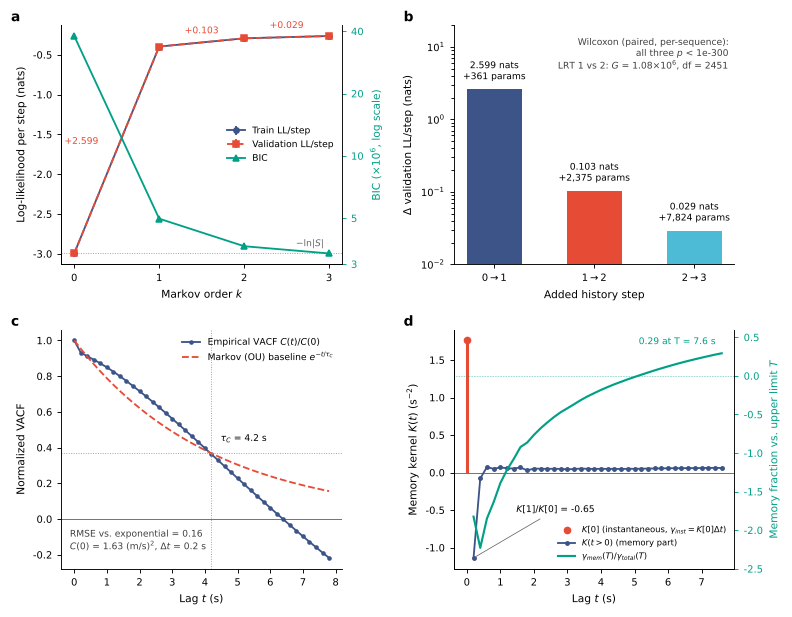

In [6]:
NPG = ['#E64B35', '#4DBBD5', '#00A087', '#3C5488', '#F39B7F', '#8491B4', '#91D1C2', '#DC0000', '#7E6148', '#B09C85']

def nature_style():
    plt.rcParams.update({
        'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
        'font.size': 7, 'axes.labelsize': 7, 'axes.titlesize': 7.5, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5,
        'legend.fontsize': 6, 'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
        'xtick.major.size': 2.5, 'ytick.major.size': 2.5, 'axes.spines.top': False, 'axes.spines.right': False,
        'legend.frameon': False, 'figure.dpi': 130, 'savefig.dpi': 600, 'savefig.bbox': 'tight',
        'pdf.fonttype': 42, 'ps.fonttype': 42, 'axes.unicode_minus': False, 'lines.linewidth': 1.2})

def panel_label(ax, s, x=-0.18, y=1.06):
    ax.text(x, y, s, transform=ax.transAxes, fontsize=9, fontweight='bold', va='top', ha='left')

nature_style()
fig, axs = plt.subplots(2, 2, figsize=(7.2, 5.6))
(a, b), (c, d) = axs
ks = summary_A['k'].to_numpy()

# --- a: LL/step 与 BIC ---
a.errorbar(ks, summary_A.train_ll_mean, yerr=summary_A.train_ll_std, marker='o', ms=3.5, color=NPG[3], label='Train LL/step')
a.errorbar(ks, summary_A.val_ll_mean, yerr=summary_A.val_ll_std, marker='s', ms=3.5, color=NPG[0], label='Validation LL/step', ls='--')
for k in range(len(ks) - 1):
    a.annotate(f'+{deltas_A[f"{k}->{k+1}"]:.3f}', xy=(k + 0.5, 0.5 * (val[k] + val[k + 1])),
               xytext=(-12, 4) if k == 0 else (0, 6), textcoords='offset points', ha='right' if k == 0 else 'center', fontsize=6, color=NPG[0])
a.axhline(-np.log(CFG['n_states']), color='0.6', lw=0.6, ls=':')
a.text(2.95, -np.log(CFG['n_states']) + 0.08, r'$-\ln|S|$', fontsize=6, color='0.4', ha='right')
a.set_xlabel('Markov order $k$'); a.set_ylabel('Log-likelihood per step (nats)'); a.set_xticks(ks)
a2 = a.twinx(); a2.spines['right'].set_visible(True)
a2.plot(ks, summary_A.bic_mean / 1e6, marker='^', ms=3.5, color=NPG[2], label='BIC')
a2.set_ylabel(r'BIC ($\times10^6$, log scale)', color=NPG[2]); a2.tick_params(axis='y', colors=NPG[2]); a2.set_yscale('log')
a2.set_yticks([3, 5, 10, 20, 40]); a2.set_yticklabels(['3', '5', '10', '20', '40']); a2.minorticks_off()
h1, l1 = a.get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels()
a.legend(h1 + h2, l1 + l2, loc='center right'); panel_label(a, 'a')

# --- b: 增量的几何衰减 vs 参数代价 ---
dv = np.array(list(deltas_A.values())); dp = np.diff(summary_A.n_params_eff.to_numpy())
xb = np.arange(len(dv))
b.bar(xb, dv, color=[NPG[3], NPG[0], NPG[1]], width=0.55)
for i, (v_, p_) in enumerate(zip(dv, dp)):
    b.text(i, v_ * 1.25, f'{v_:.3f} nats\n+{p_:,.0f} params', ha='center', va='bottom', fontsize=6)
b.set_yscale('log'); b.set_ylim(1e-2, 20)
b.set_xticks(xb); b.set_xticklabels([r'$0\to1$', r'$1\to2$', r'$2\to3$'])
b.set_xlabel('Added history step'); b.set_ylabel(r'$\Delta$ validation LL/step (nats)')
b.text(0.98, 0.95, f"Wilcoxon (paired, per-sequence):\nall three $p$ < 1e-300\nLRT 1 vs 2: $G$ = {lrt['G_statistic']/1e6:.2f}×10$^6$, df = {lrt['df_empirical']}",
       transform=b.transAxes, ha='right', va='top', fontsize=6, color='0.25')
panel_label(b, 'b')

# --- c: VACF vs 指数基准 ---
c.plot(t_C, C, color=NPG[3], marker='o', ms=2, label='Empirical VACF $C(t)/C(0)$')
c.plot(t_C, np.exp(-t_C / tau_C), color=NPG[0], ls='--', label=r'Markov (OU) baseline $e^{-t/\tau_C}$')
c.axhline(1 / np.e, color='0.6', lw=0.6, ls=':'); c.axhline(0, color='0.3', lw=0.5)
c.axvline(tau_C, color='0.6', lw=0.6, ls=':')
c.annotate(rf'$\tau_C$ = {tau_C:.1f} s', xy=(tau_C, 1 / np.e), xytext=(6, 8), textcoords='offset points', fontsize=6)
c.set_xlabel('Lag $t$ (s)'); c.set_ylabel('Normalized VACF'); c.legend(loc='upper right')
c.text(0.03, 0.08, f'RMSE vs. exponential = {rmse_exp:.2f}\n$C(0)$ = {C0:.2f} (m/s)$^2$, $\\Delta t$ = {dt:.1f} s',
       transform=c.transAxes, fontsize=6, color='0.25')
panel_label(c, 'c')

# --- d: 记忆核与窗口敏感性 ---
d.axhline(0, color='0.3', lw=0.5)
d.vlines(t_K[0], 0, K[0], color=NPG[0], lw=2); d.plot(t_K[0], K[0], 'o', color=NPG[0], ms=4, label=r'$K[0]$ (instantaneous, $\gamma_{inst}=K[0]\Delta t$)')
d.plot(t_K[1:], K[1:], marker='o', ms=2.2, color=NPG[3], label=r'$K(t>0)$ (memory part)')
d.set_xlabel('Lag $t$ (s)'); d.set_ylabel(r'Memory kernel $K(t)$ (s$^{-2}$)')
d.annotate(f'$K[1]/K[0]$ = {K[1]/K[0]:+.2f}', xy=(t_K[1], K[1]), xytext=(28, 30), textcoords='offset points', fontsize=6,
           arrowprops=dict(arrowstyle='-', lw=0.5, color='0.4'))
d2 = d.twinx(); d2.spines['right'].set_visible(True)
frac_T = gamma_mem_T / (gamma_inst + gamma_mem_T)
d2.plot(t_K[1:], frac_T, color=NPG[2], lw=1.4, label=r'$\gamma_{mem}(T)/\gamma_{total}(T)$')
d2.axhline(0, color=NPG[2], lw=0.4, ls=':')
d2.set_ylabel('Memory fraction vs. upper limit $T$', color=NPG[2]); d2.tick_params(axis='y', colors=NPG[2])
d2.set_ylim(-2.5, 0.6)
d2.annotate(f'{frac_T[-1]:.2f} at T = {t_K[-1]:.1f} s', xy=(t_K[-1], frac_T[-1]), xytext=(-4, 6), textcoords='offset points', ha='right', fontsize=6, color=NPG[2])
h1, l1 = d.get_legend_handles_labels(); h2, l2 = d2.get_legend_handles_labels()
d.legend(h1 + h2, l1 + l2, loc='lower right', fontsize=5.5); panel_label(d, 'd')

fig.tight_layout(w_pad=2.0, h_pad=1.5)
for ext in ('png', 'pdf'):
    fig.savefig(os.path.join(OUTPUT_DIR, f'fig_highD_memory.{ext}'))
print('已保存:', os.path.join(OUTPUT_DIR, 'fig_highD_memory.png / .pdf'))

## 6. 综合结论与局限

**三条证据线一致**：在"仅以当前有向纵向速度为状态"的表示下，highD 高速公路车辆的速度过程不是一阶马尔科夫的。

| 证据 | 关键数字 | 稳健性 |
|---|---|---|
| A 阶数比较 | $\Delta_{1\to2}=+0.103$, $\Delta_{2\to3}=+0.029$ nats（验证集，5 次划分） | 高：train≈val，三次配对检验均显著 |
| B LRT | $G=1.08\times10^6$，$\Delta LL/\text{step}=+0.070$ | 高（但大样本下 $p$ 本身信息量小） |
| C VACF / 记忆核 | VACF 非指数；$K[1]/K[0]=-0.65$ | 定性结构稳健；积分量 $\gamma_{\text{mem}}$ 对窗口敏感 |

**解释**：记忆主要集中在一步历史（$s_{t-1}$），收益随阶数几何衰减。最自然的机制是"状态压缩后的表观记忆"：当前速度不编码加速度、目标巡航速度与车间交互，而这些信息部分保留在过去的速度序列里。GLE 记忆核在首个滞后处的负修正正对应"加速度有惯性"。

**局限与下一步**：

1. 状态扩展为 $(v, a)$、再加入车头时距/相对速度/车道信息，检验高阶项的边际贡献是否被吸收。
2. 方法 C：改用全局均值或只用长度 ≥ 3 倍最大滞后的轨迹估计 VACF（`vacf_mean_mode='global'`），以消除有限长度偏差；对位置噪声做灵敏度分析。
3. 方法 A 的配对检验只用了 split 0；各阶评估的步数因丢弃前 $k$ 步而略有差异（相对 $7.9\times10^6$ 步可忽略）。
4. 结果针对有向速度；速率 $|v|$ 的结论需重算。